### <font color='gold'> Import les librairies requises

In [1]:
# Importer  packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###<font color='gold'> Importer et lire les données

In [5]:
# Importer data
df = pd.read_csv('/content/drive/MyDrive/heartdisease/heart_disease.csv')

#### Description des variables du jeu de données "Heart Disease"

Ce jeu de données (base de la Cleveland Clinic Foundation, UCI) contient des informations cliniques sur des patients examinés pour une maladie cardiaque. L'objectif est d'effectuer une segmentation (clustering) des patients pour identifier des groupes homogènes.

| Variable | Type | Description |
|----------|------|-------------|
| `age` | Numérique | Âge du patient (en années). |
| `sex` | Numérique | Sexe du patient (1 = homme, 0 = femme). |
| `cp` | Numérique | Type de douleur thoracique (1 = angine typique, 2 = angine atypique, 3 = douleur non angineuse, 4 = asymptomatique). |
| `trestbps` | Numérique | Tension artérielle au repos (en mm Hg). |
| `chol` | Numérique | Cholestérol sérique (en mg/dl). |
| `fbs` | Numérique | Glycémie à jeun supérieure à 120 mg/dl (1 = oui, 0 = non). |
| `restecg` | Numérique | Résultat de l'électrocardiogramme au repos (0, 1 ou 2). |
| `thalach` | Numérique | Fréquence cardiaque maximale atteinte. |
| `exang` | Numérique | Angine induite par l'effort (1 = oui, 0 = non). |
| `oldpeak` | Numérique | Dépression du segment ST induite par l'effort par rapport au repos. |
| `slope` | Numérique | Pente du segment ST à l'effort maximal (1 = ascendante, 2 = plate, 3 = descendante). |
| `ca` | Numérique | Nombre de vaisseaux principaux colorés par fluoroscopie (0 à 3). |
| `thal` | Numérique | Thalassémie (3 = normale, 6 = défaut fixe, 7 = défaut réversible). |


In [6]:
# Afficher les données
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


In [7]:
# Dimension des données
df.shape

(297, 13)

In [8]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
dtypes: float64(13)
memory usage: 30.3 KB


In [9]:
# décrire les données
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,3.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,4.730640
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,1.938629
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


### <font color='gold'> Preparation des données

In [10]:
# renommer les index
df.index = ['Patient ' + str(i) for i in range(1, len(df) + 1)]
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
Patient 1,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
Patient 2,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
Patient 3,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
Patient 4,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
Patient 5,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


In [11]:
# Données en format matriciel
x = df.values

In [12]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)

In [13]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Entrainer le modèle
pca_model.fit(x)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PCA1', 'PCA2'])

In [14]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(94.41)

### <font color='gold'> Kmeans

In [15]:
# Importer KMeans
from sklearn.cluster import KMeans

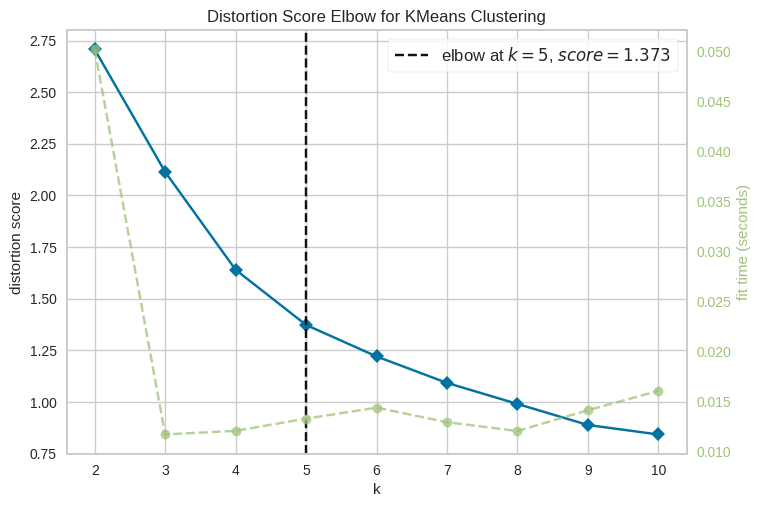

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [16]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

In [17]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 5, init = 'random', max_iter = 500, random_state = 42)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=5, random_state=42)

#### <font color='teal'> Prédiction

In [18]:
# Prediction de la partition des données
Pred = kmeans_model.predict(x)
# Afficher la partition
Pred

array([0, 4, 0, 3, 3, 3, 1, 4, 1, 2, 2, 1, 1, 1, 2, 2, 3, 3, 1, 1, 3, 1,
       1, 3, 0, 3, 1, 0, 3, 0, 0, 3, 4, 3, 3, 3, 0, 4, 4, 0, 0, 2, 0, 2,
       1, 3, 0, 0, 4, 2, 3, 2, 1, 3, 1, 4, 3, 3, 1, 0, 4, 2, 0, 1, 0, 1,
       2, 3, 4, 0, 0, 1, 4, 1, 3, 4, 1, 4, 3, 4, 3, 1, 1, 0, 1, 3, 1, 3,
       1, 1, 2, 0, 2, 3, 1, 1, 0, 2, 3, 3, 3, 1, 1, 3, 1, 2, 0, 1, 1, 4,
       1, 2, 4, 4, 0, 2, 2, 4, 0, 1, 4, 1, 0, 1, 3, 0, 1, 3, 3, 1, 1, 3,
       3, 3, 1, 2, 4, 0, 3, 3, 0, 3, 4, 1, 1, 4, 3, 1, 1, 1, 4, 4, 0, 4,
       4, 1, 1, 1, 1, 3, 1, 3, 1, 3, 3, 1, 1, 2, 0, 0, 0, 4, 0, 4, 1, 0,
       1, 3, 1, 4, 3, 0, 1, 2, 3, 0, 0, 0, 2, 4, 4, 0, 4, 0, 0, 1, 0, 1,
       0, 2, 4, 3, 4, 1, 0, 1, 0, 3, 3, 3, 2, 3, 3, 3, 0, 4, 3, 1, 1, 3,
       4, 1, 3, 3, 0, 0, 0, 2, 4, 2, 4, 2, 4, 4, 1, 1, 1, 1, 1, 1, 0, 0,
       4, 1, 4, 3, 0, 0, 0, 4, 1, 1, 3, 1, 0, 0, 1, 1, 4, 3, 3, 2, 4, 0,
       3, 2, 0, 0, 4, 2, 2, 0, 1, 3, 0, 0, 4, 3, 0, 3, 2, 4, 0, 3, 3, 0,
       1, 2, 2, 0, 2, 0, 0, 1, 2, 2, 3], dtype=int3

In [19]:
# Nombre d'observations dans chaque classe
val = pd.Series(Pred).value_counts()

In [20]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [21]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PCA1', y='PCA2', color=Pred.astype(str))
  fig.show()

In [22]:
# Visualiser les classes
bar_plot(val)
scatter_plot(New_df, Pred)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [23]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_KM = silhouette_score(x, Pred)
sil_KM

np.float64(0.3019635261082595)

### <font color='gold'> CAH

In [24]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

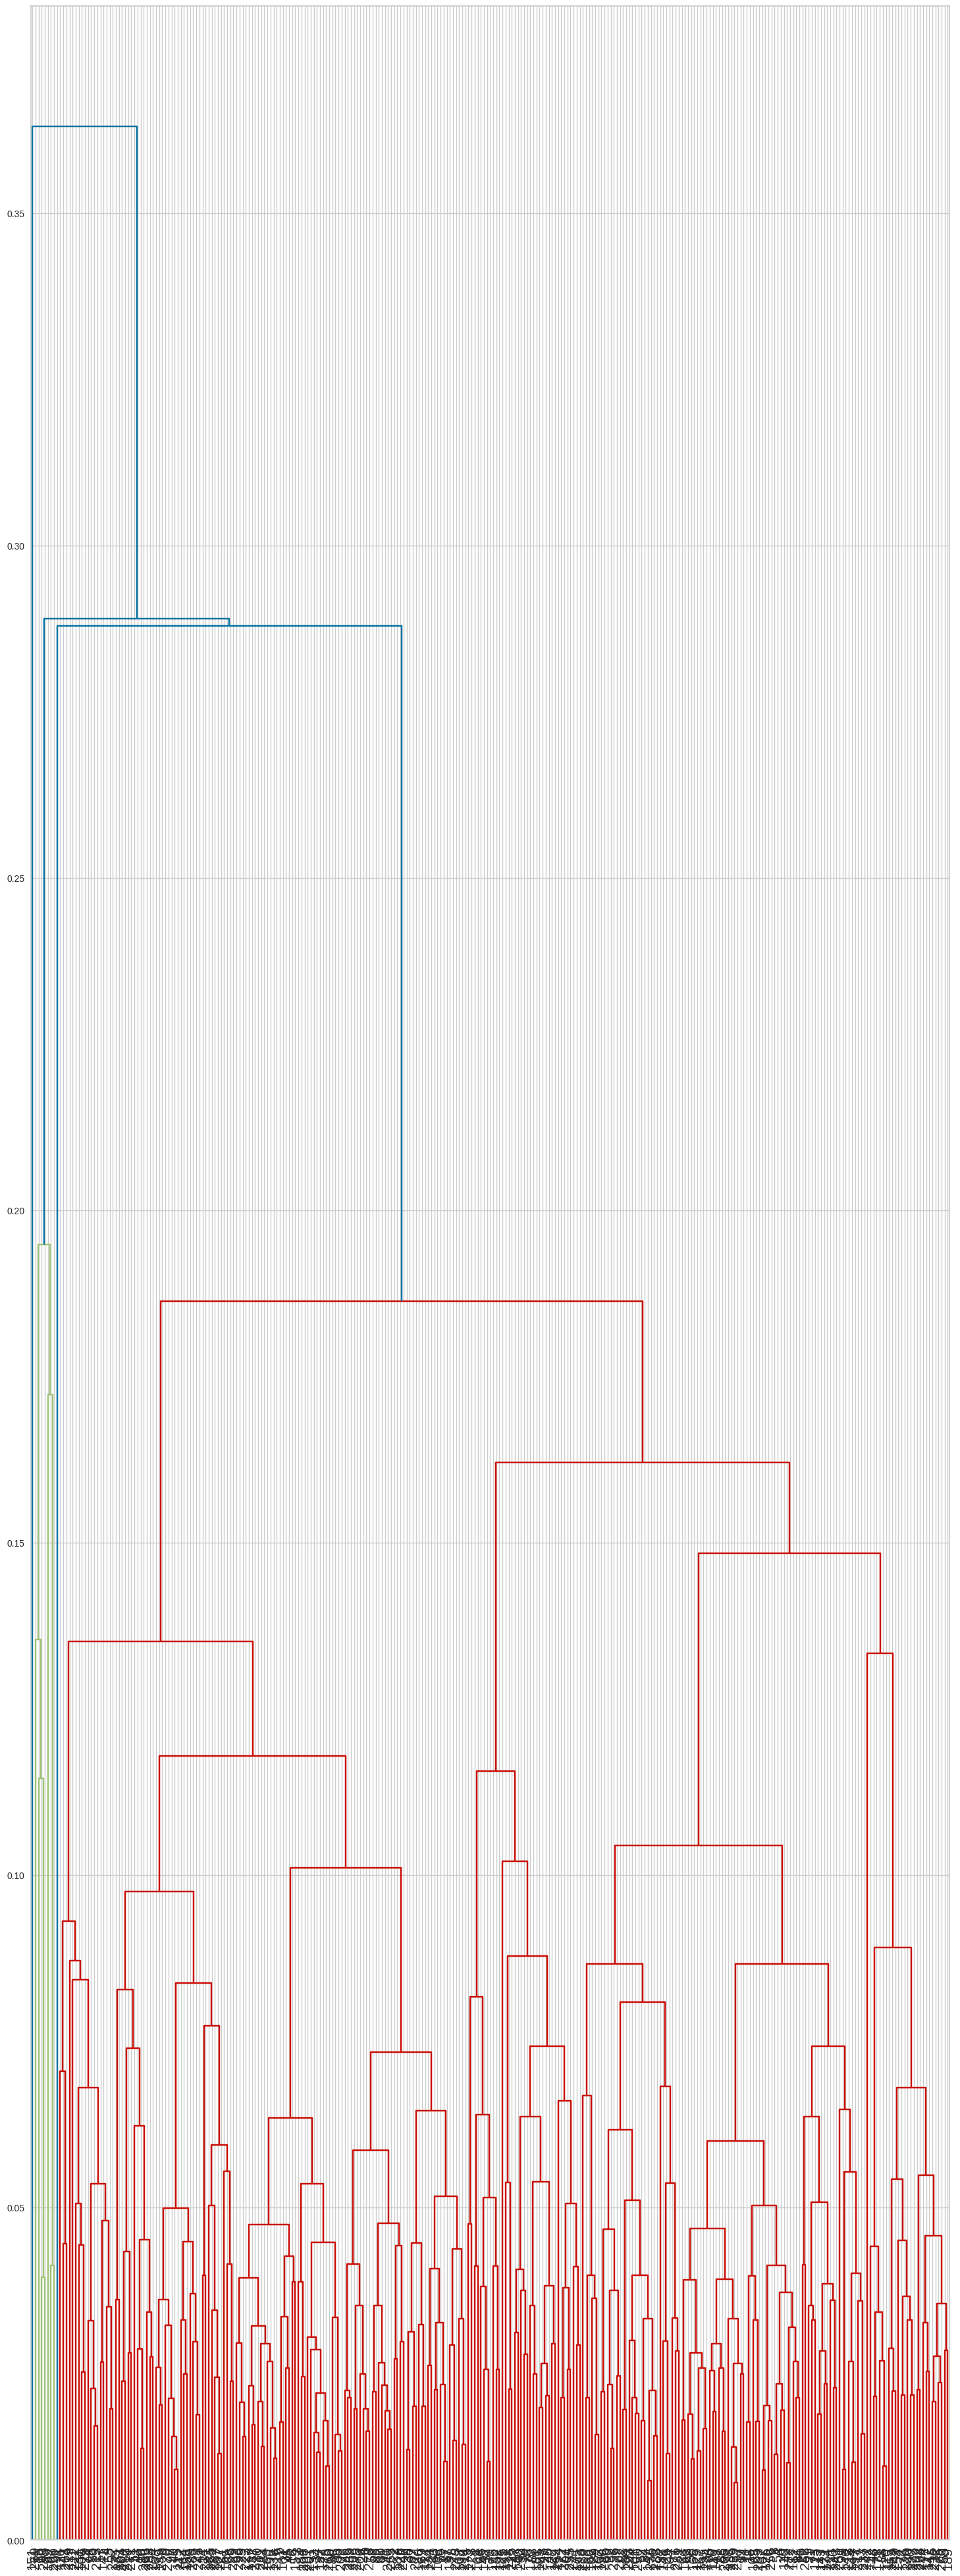

In [25]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [27]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters = 5, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average', n_clusters=5)

In [28]:
# Prédire la partition des données
pred = cah_model.fit_predict(x)
# Afficher la partition
pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 2, 4, 0, 0, 0, 1, 0])

In [29]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(pred).value_counts()
val1

,count
0,288
1,4
2,3
3,1
4,1


In [30]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [31]:
# Visualiser les classes
scatter_plot(New_df, pred)

In [32]:
# Silhouette score
sil_CAH = silhouette_score(x, pred)
sil_CAH

np.float64(0.25756268657795284)

In [33]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_KM, sil_CAH]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [34]:
# les indidivus
df.assign(Classe = Pred)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Classe
Patient 1,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
Patient 2,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,4
Patient 3,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,0
Patient 4,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,3
Patient 5,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Patient 293,57.0,0.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0,0
Patient 294,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
Patient 295,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
Patient 296,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,2


In [35]:
# Les individus de la classe 0
df[Pred == 0]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
Patient 1,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
Patient 3,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
Patient 25,60.0,1.0,4.0,130.0,206.0,0.0,2.0,132.0,1.0,2.4,2.0,2.0,7.0
Patient 28,66.0,0.0,1.0,150.0,226.0,0.0,0.0,114.0,0.0,2.6,3.0,0.0,3.0
Patient 30,40.0,1.0,4.0,110.0,167.0,0.0,2.0,114.0,1.0,2.0,2.0,0.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Patient 283,58.0,0.0,4.0,170.0,225.0,1.0,2.0,146.0,1.0,2.8,2.0,2.0,6.0
Patient 286,67.0,1.0,3.0,152.0,212.0,0.0,2.0,150.0,0.0,0.8,2.0,0.0,7.0
Patient 290,63.0,0.0,4.0,124.0,197.0,0.0,0.0,136.0,1.0,0.0,2.0,0.0,3.0
Patient 292,59.0,1.0,4.0,164.0,176.0,1.0,2.0,90.0,0.0,1.0,2.0,2.0,6.0


## Bilan des deux méthodes

Compare les silhouettes et les profils moyens. Un score plus élevé indique généralement des groupes mieux séparés, mais il faut aussi vérifier la répartition et le sens des variables. Les numéros de groupe sont arbitraires.

La création de l’interface Streamlit se fera dans un fichier séparé afin de garder ce notebook centré sur l’analyse.

In [ ]:
comparaison = pd.DataFrame({"Méthode": ["K-means", "CAH"], "Silhouette": [sil_KM, sil_CAH]})
comparaison

In [ ]:
print("Profil moyen — K-means")
display(df.assign(Groupe=Pred).groupby("Groupe").mean(numeric_only=True).round(2))
print("Profil moyen — CAH")
display(df.assign(Groupe=pred).groupby("Groupe").mean(numeric_only=True).round(2))